# COSMOS1–4: FINALCAT-matched master catalog and band diagnostics

Build a single catalog containing **only FINALCAT sources with a 7DT match in at least one field**. Each row represents one FINALCAT row, with all matched COSMOS1–4 measurements retained in field-specific columns. SDSS information is reconciled into one common set of columns before any diagnostic analysis.

The catalog is saved to `output/singlephot/master_catalog_MatchedWithFianlcat_OverallCosmosField.fits`. All subsequent analysis reads this saved catalog. The spelling `Fianlcat` in the filename follows the requested filename.

Photometry succeeds when `source_id >= 0`, `0 < mag < 50`, and `mag_err > 0`, with finite magnitude and error. No additional S/N cut is applied. Band availability and success are combined across COSMOS1–4 per FINALCAT source: a band counts once if any matched field measured it successfully. The representative field is still selected for source inspection and tie-breaking. The 20 nominal bands are the denominator for “all bands.”

`finalcat_RM` is the Subaru r+ total AB magnitude derived from Muzzin et al. (2013) photometry using the Ks total/aperture flux ratio; see [Section 3.9, equation (4)](https://arxiv.org/html/1303.4410#S3.SS9).

## Global variables and input catalogs

In [7]:
from pathlib import Path
import json
import warnings
import numpy as np
import matplotlib.pyplot as plt
from scl_plot import scl_plt

# Apply the SNUCLUES Matplotlib defaults to subsequent figures.
scl_plt.default()
from astropy.io import fits
from astropy.table import Table, MaskedColumn
from astropy.visualization import ImageNormalize, ZScaleInterval
from astropy.wcs import WCS
from astropy.wcs.utils import proj_plane_pixel_scales
from IPython.display import display

PROJECT_ROOT = Path.cwd().resolve()
if PROJECT_ROOT.name == 'Notebooks':
    PROJECT_ROOT = PROJECT_ROOT.parent
FIELDS = (1, 2, 3, 4)
BANDS_7DT = tuple(f'm{i}' for i in range(400, 900, 25))
N_TOTAL_BANDS = len(BANDS_7DT)
MIN_SUCCESS_BANDS = 15
RANDOM_SEED = 20261015
N_EXAMPLES = 5
PIXEL_RANGE = 40
DATA_ROOT = PROJECT_ROOT / 'COSMOS_data'
OUTPUT_DIR = PROJECT_ROOT / 'output/singlephot'
OVERALL_CATALOG_PATH = OUTPUT_DIR / 'master_catalog_MatchedWithFianlcat_OverallCosmosField.fits'
ANALYSIS_DIR = OUTPUT_DIR / 'analysis/numofmatchedbands'
EXAMPLE_DIR = ANALYSIS_DIR / 'examples'
EXAMPLE_DIR.mkdir(parents=True, exist_ok=True)
FINALCAT_PATH = DATA_ROOT / 'COSMOS_finalcat.fits'
MASTER_PATHS = {field: PROJECT_ROOT / f'output/COSMOS{field}/singlephot/cosmos{field}_master_catalog.fits' for field in FIELDS}
# Load production matching links; do not perform a new 7DT–FINALCAT sky match.
finalcat = Table.read(FINALCAT_PATH)
masters = {field: Table.read(path) for field, path in MASTER_PATHS.items()}

def get_image_path(cosmos, band):
    paths = sorted((DATA_ROOT / f'COSMOS{cosmos}').glob(f'*{band}*.com.fits'))
    if len(paths) != 1:
        raise FileNotFoundError(f'Expected one COSMOS{cosmos} {band} image; found {len(paths)}')
    return paths[0]

def get_weight_path(cosmos, band):
    paths = sorted((DATA_ROOT / f'COSMOS{cosmos}').glob(f'*{band}*.weight.fits'))
    if len(paths) != 1:
        raise FileNotFoundError(f'Expected one COSMOS{cosmos} {band} weight image; found {len(paths)}')
    return paths[0]

active_by_field = {}
for field in FIELDS:
    active = []
    for band in BANDS_7DT:
        try:
            get_image_path(field, band)
            get_weight_path(field, band)
        except FileNotFoundError:
            continue
        active.append(band)
    active_by_field[field] = tuple(active)
    if not active:
        raise RuntimeError(f'COSMOS{field}: no available bands')
    print(f'COSMOS{field}: {len(masters[field]):,} master rows; {len(active)} active bands; missing: {sorted(set(BANDS_7DT) - set(active))}')
print(f'FINALCAT: {len(finalcat):,} sources; output: {ANALYSIS_DIR}')

COSMOS1: 88,361 master rows; 20 active bands; missing: []
COSMOS2: 93,083 master rows; 16 active bands; missing: ['m650', 'm675', 'm800', 'm825']
COSMOS3: 82,144 master rows; 18 active bands; missing: ['m650', 'm675']
COSMOS4: 88,378 master rows; 16 active bands; missing: ['m450', 'm475', 'm650', 'm675']
FINALCAT: 126,280 sources; output: /Users/mac_seo/Research_local/7DTonCOSMOS/output/singlephot/analysis/numofmatchedbands


## Build the FINALCAT-centered catalog

The key is `finalcat_idx`, because the original FINALCAT ID string is not always unique. Only production master rows with both `has_7dt` and `has_finalcat` enter the catalog. FINALCAT-only and 7DT-only rows are excluded from every extension.

Shared FINALCAT columns are stored once as `finalcat_*`. Every other non-SDSS column from a matched master row is retained as `7dt_cosmos{field}_{original_name}`, including the original local `master_id`, positions, source IDs, morphology, and FINALCAT matching diagnostics. Original column types, units, masks, and field metadata are preserved. The SDSS columns are deliberately reconciled rather than duplicated.

In [8]:
def numeric(table, name, default=np.nan):
    """Return numerical values while respecting FITS masks."""
    return np.asarray(np.ma.filled(table[name], default), dtype=float)


def normalized_text(values):
    return np.char.strip(np.asarray(values).astype(str))


def equal_values(left, right):
    """Compare stored values, allowing only floating-point serialization noise."""
    a, b = np.asarray(left), np.asarray(right)
    if a.dtype.kind in 'SU' or b.dtype.kind in 'SU':
        return np.array_equal(normalized_text(a), normalized_text(b))
    if a.dtype.kind == 'f' or b.dtype.kind == 'f':
        return np.allclose(a, b, rtol=1e-7, atol=1e-6, equal_nan=True)
    return np.array_equal(a, b)


# Preserve all FINALCAT columns once, and keep all field-specific measurements.
shared_finalcat_names = {f'finalcat_{name}' for name in finalcat.colnames}
field_links = {}
coverage_count = np.zeros(len(finalcat), dtype=np.int16)
for field, master in masters.items():
    idx = numeric(master, 'finalcat_idx', -1).astype(np.int64)
    linked = idx >= 0
    assert np.all(idx[linked] < len(finalcat))
    assert len(np.unique(idx[linked])) == int(linked.sum())
    coverage_count[idx[linked]] += 1
    matched = linked & np.asarray(master['has_7dt'], dtype=bool) & np.asarray(master['has_finalcat'], dtype=bool)
    assert np.array_equal(matched, normalized_text(master['master_class']) == 'matched')
    field_links[field] = (np.flatnonzero(matched), idx[matched])

matched_finalcat_indices = np.unique(np.concatenate([links[1] for links in field_links.values()]))
overall = Table(masked=True)
# Global IDs are separate from the original, field-local master IDs.
overall['master_id'] = np.arange(len(matched_finalcat_indices), dtype=np.int64)
overall['finalcat_idx'] = matched_finalcat_indices
for name in finalcat.colnames:
    overall[f'finalcat_{name}'] = finalcat[name][matched_finalcat_indices].copy()

global_row_for_finalcat = np.full(len(finalcat), -1, dtype=np.int64)
global_row_for_finalcat[matched_finalcat_indices] = np.arange(len(overall))
overall['n_COSMOS_coverage'] = coverage_count[matched_finalcat_indices]
column_map_rows = []
field_metadata_rows = []
# Store SDSS inputs only in a separate diagnostic log, not as four photometry blocks.
sdss_inputs = [[] for _ in range(len(overall))]
sdss_input_log_rows = []
SDSS_FIELDS = [
    'objid', 'ra', 'dec', 'type', 'clean', 'mode',
    *[f'petroMag_{b}' for b in 'ugriz'],
    *[f'petroMagErr_{b}' for b in 'ugriz'], 'flags', 'flags_text',
]
field_sdss_schema = masters[FIELDS[0]]
for field, master in masters.items():
    source_rows, finalcat_indices = field_links[field]
    target_rows = global_row_for_finalcat[finalcat_indices]
    has_field_match = np.zeros(len(overall), dtype=bool)
    has_field_match[target_rows] = True
    overall[f'7dt_cosmos{field}_matched'] = has_field_match
    field_metadata_rows.append((field, str(MASTER_PATHS[field].relative_to(PROJECT_ROOT)),
                                json.dumps(master.meta, default=str), json.dumps(list(active_by_field[field]))))
    for name in master.colnames:
        source = master[name][source_rows]
        if name in shared_finalcat_names:
            canonical = overall[name][target_rows]
            assert np.array_equal(np.ma.getmaskarray(source), np.ma.getmaskarray(canonical)), (field, name)
            valid = ~np.ma.getmaskarray(source)
            assert equal_values(source[valid], canonical[valid]), (field, name)
            column_map_rows.append((field, name, name, 'shared_finalcat'))
            continue
        if name.startswith('sdss_') or name == 'has_sdss':
            column_map_rows.append((field, name, name, 'reconciled_sdss'))
            continue
        output_name = f'7dt_cosmos{field}_{name}'
        data = np.zeros(len(overall), dtype=source.dtype)
        mask = np.ones(len(overall), dtype=bool)
        data[target_rows] = np.asarray(source)
        mask[target_rows] = np.ma.getmaskarray(source)
        overall[output_name] = MaskedColumn(data, mask=mask, unit=source.unit, description=source.description)
        column_map_rows.append((field, name, output_name, 'field_specific'))
    for source_row, target_row in zip(source_rows, target_rows):
        row = master[int(source_row)]
        has_sdss = bool(row['has_sdss'])
        objid = int(row['sdss_objid']) if has_sdss and not np.ma.is_masked(row['sdss_objid']) else -1
        sdss_input_log_rows.append((int(target_row), int(row['finalcat_idx']), field,
                                    int(row['master_id']), has_sdss, objid,
                                    float(row['sdss_sep_arcsec']) if has_sdss else np.nan,
                                    str(row['sdss_match_status'])))
        if has_sdss:
            sdss_inputs[int(target_row)].append((field, {
                name: row[f'sdss_{name}'] for name in SDSS_FIELDS
            }))

overall['n_COSMOS_7dt_matches'] = sum(np.asarray(overall[f'7dt_cosmos{f}_matched'], dtype=np.int16) for f in FIELDS)
assert np.all(np.asarray(overall['n_COSMOS_7dt_matches']) >= 1)
assert len(np.unique(overall['master_id'])) == len(overall)
assert len(np.unique(overall['finalcat_idx'])) == len(overall)
print(f'Unified catalog: {len(overall):,} FINALCAT-matched sources')
print(f'Initial columns before common SDSS information and band summaries: {len(overall.colnames)}')

Unified catalog: 9,326 FINALCAT-matched sources
Initial columns before common SDSS information and band summaries: 642


## Reconcile SDSS information

Agreement is based on SDSS objID and the stored object properties, not on the field-specific match distance. Reuse an agreed object after checking its distance from the FINALCAT position. Query SDSS DR17 again for conflicting objIDs, inconsistent properties, objects outside the common 1.5-arcsec radius, and objIDs claimed by more than one FINALCAT source.

Consistent, uniquely assigned matches are retained. For rechecked sources, prefer a unique, positionally valid FINALCAT SDSS objID when available; otherwise require a unique, uncontested candidate. Ambiguous candidates remain masked in the common SDSS columns. Detailed inputs, requery candidates, and decisions are saved separately. Sources with no input SDSS match remain unmatched.

In [9]:
from collections import Counter, defaultdict
from urllib.parse import urlencode
from urllib.request import urlopen
from astropy.io import ascii
from astropy.coordinates import SkyCoord
import astropy.units as u
import hashlib

SDSS_DATA_RELEASE = 17
SDSS_MATCH_RADIUS_ARCSEC = 1.5
SDSS_REQUERY_DIR = ANALYSIS_DIR / 'sdss_requery'
SDSS_REQUERY_DIR.mkdir(parents=True, exist_ok=True)
finalcat_coordinates = SkyCoord(numeric(overall, 'finalcat_RA') * u.deg,
                               numeric(overall, 'finalcat_DEC') * u.deg)


def sdss_separation(row_index, payload):
    """Use one coordinate reference for every field: the FINALCAT position."""
    ra, dec = payload['ra'], payload['dec']
    if np.ma.is_masked(ra) or np.ma.is_masked(dec) or not np.isfinite(float(ra)) or not np.isfinite(float(dec)):
        return np.inf
    return float(finalcat_coordinates[row_index].separation(SkyCoord(float(ra) * u.deg, float(dec) * u.deg)).arcsec)


def payloads_equal(left, right):
    for name in SDSS_FIELDS:
        left_mask, right_mask = np.ma.is_masked(left[name]), np.ma.is_masked(right[name])
        if left_mask != right_mask:
            return False
        if not left_mask and not equal_values([left[name]], [right[name]]):
            return False
    return True


def query_sdss_positions(row_indices):
    """Requery disputed sources with small indexed searches and persistent caches."""
    from concurrent.futures import ThreadPoolExecutor, as_completed
    import time

    def fetch_one(row_index):
        ra = float(overall['finalcat_RA'][row_index])
        dec = float(overall['finalcat_DEC'][row_index])
        radius_arcmin = (SDSS_MATCH_RADIUS_ARCSEC + 0.01) / 60.0
        fields = [f'p.{name}' for name in SDSS_FIELDS if name != 'flags_text']
        fields.append('dbo.fPhotoFlagsN(p.flags) AS flags_text')
        sql = (f"SELECT {', '.join(fields)} FROM dbo.fGetNearbyObjEq({ra:.10f}, {dec:.10f}, {radius_arcmin:.10f}) nearby "
               "JOIN PhotoObj p ON p.objid = nearby.objid WHERE p.mode = 1")
        cache_key = hashlib.sha256(sql.encode()).hexdigest()[:16]
        cache_path = SDSS_REQUERY_DIR / f'dr17_candidates_{cache_key}.fits'
        if cache_path.exists():
            downloaded = Table.read(cache_path)
            if not set(SDSS_FIELDS).issubset(downloaded.colnames):
                raise ValueError(f'Invalid SDSS candidate cache: {cache_path}')
            return downloaded
        errors = []
        for attempt in range(5):
            try:
                # A cache-busting parameter avoids replaying a transient HTTP error.
                params = {'cmd': sql, 'format': 'csv', '_': str(time.time_ns())}
                endpoint = 'https://skyserver.sdss.org/dr17/SkyServerWS/SearchTools/SqlSearch?'
                with urlopen(endpoint + urlencode(params), timeout=45) as response:
                    payload = response.read().decode('utf-8')
                downloaded = ascii.read(payload, format='csv', comment='#')
                if not set(SDSS_FIELDS).issubset(downloaded.colnames):
                    raise ValueError('SDSS response is missing requested columns')
                if len(downloaded):
                    assert np.all(np.asarray(downloaded['mode'], dtype=int) == 1)
                    assert np.all(np.isfinite(numeric(downloaded, 'ra')) & np.isfinite(numeric(downloaded, 'dec')))
                    assert len(np.unique(downloaded['objid'])) == len(downloaded)
                downloaded.meta['SDSS_DR'] = SDSS_DATA_RELEASE
                downloaded.meta['QUERY'] = sql
                downloaded.write(cache_path, overwrite=True)
                return downloaded
            except Exception as exc:
                errors.append(f'{type(exc).__name__}: {exc}')
                if attempt < 4:
                    time.sleep(min(1 + attempt, 4))
        raise RuntimeError(f"SDSS requery failed for global master_id={int(overall['master_id'][row_index])}: " + ' | '.join(errors))

    # Limit concurrent requests to avoid overloading the SDSS service.
    all_payloads = {}
    completed = 0
    with ThreadPoolExecutor(max_workers=3) as executor:
        futures = [executor.submit(fetch_one, row_index) for row_index in row_indices]
        for future in as_completed(futures):
            downloaded = future.result()
            for row in downloaded:
                all_payloads[int(row['objid'])] = {name: row[name] for name in SDSS_FIELDS}
            completed += 1
            if completed % 20 == 0 or completed == len(row_indices):
                print(f'SDSS requery: {completed}/{len(row_indices)} targets completed')
    return all_payloads


# Identify disagreements before resolving any assignments.
reasons = [[] for _ in range(len(overall))]
input_objids = []
n_field_matches = np.zeros(len(overall), dtype=np.int16)
field_mask = np.zeros(len(overall), dtype=np.uint8)
objid_owners = defaultdict(set)
for i, inputs in enumerate(sdss_inputs):
    ids = {int(payload['objid']) for field, payload in inputs}
    input_objids.append(ids)
    n_field_matches[i] = len(inputs)
    for field, payload in inputs:
        field_mask[i] |= 1 << (field - 1)
        objid_owners[int(payload['objid'])].add(i)
    if len(ids) > 1:
        reasons[i].append('different_objids')
    if inputs and len(ids) == 1 and any(not payloads_equal(inputs[0][1], p) for field, p in inputs[1:]):
        reasons[i].append('different_properties')
    if any(sdss_separation(i, p) > SDSS_MATCH_RADIUS_ARCSEC for field, p in inputs):
        reasons[i].append('outside_finalcat_radius')
for objid, owners in objid_owners.items():
    if len(owners) > 1:
        for i in owners:
            reasons[i].append('shared_objid_between_finalcat_sources')
requery_rows = [i for i, reason in enumerate(reasons) if reason]
print(f'SDSS requery targets: {len(requery_rows)}; reasons: {dict(Counter(r for row in reasons for r in row))}')
requeried_payloads = query_sdss_positions(requery_rows) if requery_rows else {}

assigned = {}
methods = np.full(len(overall), 'no_input_match', dtype='<U40')
options = {}
# Reserve consistent matches first; disputed targets cannot steal an agreed object.
for i, inputs in enumerate(sdss_inputs):
    if inputs and not reasons[i]:
        assigned[i] = inputs[0][1]
        methods[i] = 'consistent_fields' if len(inputs) > 1 else 'single_field'
reserved_ids = {int(payload['objid']) for payload in assigned.values()}
candidate_log_rows = []
for i in requery_rows:
    candidates = {}
    for objid, payload in requeried_payloads.items():
        sep = sdss_separation(i, payload)
        if sep <= SDSS_MATCH_RADIUS_ARCSEC:
            candidates[objid] = payload
            candidate_log_rows.append((int(overall['master_id'][i]), int(overall['finalcat_idx'][i]), objid, sep, objid in reserved_ids))
    options[i] = candidates
    methods[i] = 'ambiguous' if candidates else 'requery_no_candidate'

# A valid FINALCAT objID can disambiguate a candidate only if its claim is unique.
preferred_claims = defaultdict(list)
for i, candidates in options.items():
    raw = overall['finalcat_SDSS_OBJID'][i]
    text = '' if np.ma.is_masked(raw) else str(raw).strip()
    if text.isdigit():
        objid = int(text)
        if objid in candidates and objid not in reserved_ids:
            preferred_claims[objid].append(i)
for objid, owners in preferred_claims.items():
    if len(owners) == 1:
        i = owners[0]
        assigned[i] = options[i][objid]
        reserved_ids.add(objid)
        methods[i] = 'requery_finalcat_objid'

# Remaining matches must be unambiguous in both directions.
# Keep the original candidate set: an ambiguous two-candidate target does not
# become a confident match merely because a competitor claimed one candidate.
remaining_owners = defaultdict(set)
for i, candidates in options.items():
    if i not in assigned:
        for objid in candidates:
            remaining_owners[objid].add(i)
for i, candidates in options.items():
    if i in assigned or len(candidates) != 1:
        continue
    objid = next(iter(candidates))
    if objid not in reserved_ids and len(remaining_owners[objid]) == 1:
        assigned[i] = candidates[objid]
        reserved_ids.add(objid)
        methods[i] = 'requery_unique'

has_sdss = np.zeros(len(overall), dtype=bool)
has_sdss[list(assigned)] = True
overall['has_sdss'] = has_sdss
overall['sdss_match_status'] = methods
overall['sdss_match_method'] = methods.copy()
overall['sdss_n_field_matches'] = n_field_matches
overall['sdss_n_distinct_objids'] = np.asarray([len(ids) for ids in input_objids], dtype=np.int16)
# Bits 0–3 identify COSMOS1–4 input matches, before reconciliation.
overall['sdss_field_mask'] = field_mask
overall['sdss_conflict'] = np.asarray([bool(reason) for reason in reasons])
overall['sdss_requeried'] = np.asarray([bool(reason) for reason in reasons])
candidate_owners = defaultdict(set)
for i in range(len(overall)):
    if i in options:
        for objid in options[i]:
            candidate_owners[objid].add(i)
    elif i in assigned:
        candidate_owners[int(assigned[i]['objid'])].add(i)
overall['sdss_n_master_candidates'] = np.asarray([len(candidate_owners[int(assigned[i]['objid'])]) if i in assigned else 0 for i in range(len(overall))], dtype=np.int16)
overall['sdss_n_candidates'] = np.asarray([len(options[i]) if i in options else int(bool(sdss_inputs[i])) for i in range(len(overall))], dtype=np.int16)
separations = np.full(len(overall), np.nan)
for i, payload in assigned.items():
    separations[i] = sdss_separation(i, payload)
overall['sdss_sep_arcsec'] = MaskedColumn(separations, mask=~has_sdss, unit='arcsec')
for name in SDSS_FIELDS:
    source = field_sdss_schema[f'sdss_{name}']
    output_dtype = source.dtype
    if source.dtype.kind in 'SU':
        # Field caches may use different string widths; never truncate SDSS flags.
        width = max([masters[field][f'sdss_{name}'].dtype.itemsize for field in FIELDS]
                    + [len(str(payload[name])) for payload in assigned.values() if not np.ma.is_masked(payload[name])])
        output_dtype = np.dtype(f'S{width}')
    data = np.zeros(len(overall), dtype=output_dtype)
    mask = np.ones(len(overall), dtype=bool)
    for i, payload in assigned.items():
        if not np.ma.is_masked(payload[name]):
            data[i] = payload[name]
            mask[i] = False
    overall[f'sdss_{name}'] = MaskedColumn(data, mask=mask, unit=source.unit)
# Check common object properties before writing the reconciled catalog.
for i, payload in assigned.items():
    for name in SDSS_FIELDS:
        if not np.ma.is_masked(payload[name]):
            assert equal_values([overall[f'sdss_{name}'][i]], [payload[name]]), (i, name)
assert len({int(payload['objid']) for payload in assigned.values()}) == len(assigned)
assert np.all(separations[has_sdss] <= SDSS_MATCH_RADIUS_ARCSEC)
assert not any('_sdss_' in name for name in overall.colnames if name.startswith('7dt_cosmos'))

input_log = Table(rows=sdss_input_log_rows, names=['master_id', 'finalcat_idx', 'COSMOS', 'field_master_id', 'has_sdss', 'sdss_objid', 'field_sep_arcsec', 'field_match_status'])
input_log.write(ANALYSIS_DIR / 'sdss_field_input_matches.csv', format='ascii.csv', overwrite=True)
candidate_log = Table(rows=candidate_log_rows, names=['master_id', 'finalcat_idx', 'sdss_objid', 'sep_arcsec', 'reserved_by_consistent_match'], dtype=['i8', 'i8', 'i8', 'f8', 'bool'])
candidate_log.write(ANALYSIS_DIR / 'sdss_requery_candidate_matches.csv', format='ascii.csv', overwrite=True)
resolution_log = Table()
resolution_log['master_id'] = overall['master_id']
resolution_log['finalcat_idx'] = overall['finalcat_idx']
resolution_log['input_objids'] = [','.join(map(str, sorted(ids))) for ids in input_objids]
resolution_log['requery_reason'] = [';'.join(reason) for reason in reasons]
resolution_log['resolution'] = methods
resolution_log['selected_objid'] = np.ma.filled(overall['sdss_objid'], -1)
resolution_log.write(ANALYSIS_DIR / 'sdss_resolution_log.csv', format='ascii.csv', overwrite=True)
print('Unified SDSS outcomes:', dict(Counter(methods)))

SDSS requery targets: 122; reasons: {'shared_objid_between_finalcat_sources': 119, 'outside_finalcat_radius': 2, 'different_objids': 1}
SDSS requery: 20/122 targets completed
SDSS requery: 40/122 targets completed
SDSS requery: 60/122 targets completed
SDSS requery: 80/122 targets completed
SDSS requery: 100/122 targets completed
SDSS requery: 120/122 targets completed
SDSS requery: 122/122 targets completed
Unified SDSS outcomes: {'single_field': 5202, 'no_input_match': 944, 'consistent_fields': 3058, 'ambiguous': 94, 'requery_unique': 1, 'requery_finalcat_objid': 26, 'requery_no_candidate': 1}


## Band summaries, FITS persistence, and reload

All matched field measurements remain in the catalog. Per-field success flags are combined by band across COSMOS1–4, counting a source at most once per band. The representative field is retained for inspection cutouts and diagnostics that need one field's image and local master ID.

The FITS file contains `CATALOG`, `COLUMN_MASKS`, `FIELD_METADATA`, and `COLUMN_MAP`. `COLUMN_MASKS` stores a compact bit mask for every column, including Boolean and string columns, allowing exact recovery through `read_overall_catalog`. The metadata and mapping extensions contain schema/provenance only, with no additional source rows.

In [10]:
def successful_field_photometry(catalog, field, active_bands):
    """Count valid photometry in this field without combining different fields."""
    prefix = f'7dt_cosmos{field}_'
    success = np.zeros((len(catalog), N_TOTAL_BANDS), dtype=bool)
    detected = np.zeros_like(success)
    errors = np.full(success.shape, np.nan)
    for j, band in enumerate(BANDS_7DT):
        sid = numeric(catalog, f'{prefix}{band}_source_id', -1)
        mag = numeric(catalog, f'{prefix}{band}_mag')
        err = numeric(catalog, f'{prefix}{band}_mag_err')
        detected[:, j] = sid >= 0
        success[:, j] = detected[:, j] & np.isfinite(mag) & (mag > 0) & (mag < 50) & np.isfinite(err) & (err > 0)
        if band not in active_bands:
            assert not detected[:, j].any(), (field, band)
            success[:, j] = False
        errors[success[:, j], j] = err[success[:, j]]
    with warnings.catch_warnings():
        warnings.simplefilter('ignore', RuntimeWarning)
        median_error = np.nanmedian(errors, axis=1)
    return success, detected, median_error


n_fields = len(FIELDS)
success_count = np.zeros((len(overall), n_fields), dtype=np.int16)
field_band_success = np.zeros((len(overall), n_fields, N_TOTAL_BANDS), dtype=bool)
field_band_detected = np.zeros_like(field_band_success)
median_error = np.full((len(overall), n_fields), np.inf)
match_distance = np.full((len(overall), n_fields), np.inf)
field_present = np.column_stack([np.asarray(overall[f'7dt_cosmos{field}_matched']) for field in FIELDS])
for j, field in enumerate(FIELDS):
    success, detected, field_error = successful_field_photometry(overall, field, active_by_field[field])
    prefix = f'7dt_cosmos{field}_'
    field_band_success[:, j, :] = success
    field_band_detected[:, j, :] = detected
    for k, band in enumerate(BANDS_7DT):
        overall[f'{prefix}{band}_success'] = success[:, k]
    success_count[:, j] = success.sum(axis=1)
    median_error[:, j] = np.nan_to_num(field_error, nan=np.inf)
    match_distance[:, j] = np.nan_to_num(numeric(overall, f'{prefix}finalcat_sep_arcsec'), nan=np.inf)
    overall[f'{prefix}n_success_bands'] = success_count[:, j]
    overall[f'{prefix}n_detected_bands'] = detected.sum(axis=1).astype(np.int16)
    overall[f'{prefix}n_available_bands'] = np.full(len(overall), len(active_by_field[field]), dtype=np.int16)
    overall[f'{prefix}median_mag_err'] = MaskedColumn(field_error, mask=~field_present[:, j])
    assert np.array_equal(detected.sum(axis=1), numeric(overall, f'{prefix}n_7dt_bands', 0).astype(int))

# Rank matched fields for representative cutouts, using the best single-field photometry.
selected_column = np.empty(len(overall), dtype=np.int16)
for i in range(len(overall)):
    available = np.flatnonzero(field_present[i])
    selected_column[i] = min(available, key=lambda j: (-int(success_count[i, j]), median_error[i, j], match_distance[i, j], FIELDS[j]))
selected_fields = np.asarray(FIELDS, dtype=np.int16)[selected_column]
overall['selected_COSMOS'] = selected_fields
overall['selected_field_master_id'] = np.full(len(overall), -1, dtype=np.int64)
for field in FIELDS:
    selected = selected_fields == field
    prefix = f'7dt_cosmos{field}_'
    overall['selected_field_master_id'][selected] = overall[f'{prefix}master_id'][selected]

# Count each successful band once if any matched COSMOS field measured it.
union_success = field_band_success.any(axis=1)
union_detected = field_band_detected.any(axis=1)
union_available = np.zeros((len(overall), N_TOTAL_BANDS), dtype=bool)
for field in FIELDS:
    for band_index, band in enumerate(BANDS_7DT):
        if band in active_by_field[field]:
            union_available[:, band_index] |= field_present[:, FIELDS.index(field)]
overall['n_success_bands'] = union_success.sum(axis=1).astype(np.int16)
overall['n_detected_bands'] = union_detected.sum(axis=1).astype(np.int16)
overall['n_available_bands'] = union_available.sum(axis=1).astype(np.int16)
overall['median_mag_err'] = median_error[np.arange(len(overall)), selected_column]
overall['all_20_success'] = union_success.all(axis=1)
overall['all_available_success'] = (union_success | ~union_available).all(axis=1)
assert np.array_equal(np.asarray(overall['n_success_bands']), union_success.sum(axis=1))
assert np.all(np.asarray(overall['n_success_bands']) <= np.asarray(overall['n_available_bands']))

# Preserve all original field metadata, rather than letting four headers overwrite each other.
field_metadata = Table(rows=field_metadata_rows, names=['COSMOS', 'source_path', 'original_metadata_json', 'active_bands_json'])
column_map = Table(rows=column_map_rows, names=['COSMOS', 'original_column', 'output_column', 'treatment'])
overall.meta.update(SCHEMVER=1, ROWKEY='finalcat_idx', SDSS_DR=SDSS_DATA_RELEASE,
                    SDSSMAG='petroMag', SDSSRAD=SDSS_MATCH_RADIUS_ARCSEC,
                    NOM_BAND=N_TOTAL_BANDS, NFINAL=len(finalcat),
                    NCOVER=int((coverage_count > 0).sum()), NOUTSIDE=int((coverage_count == 0).sum()),
                    FINCAT=FINALCAT_PATH.name)


def write_overall_catalog(catalog, path, field_metadata, column_map):
    """Save normal FITS columns plus exact masks and reconstruction metadata."""
    masks = np.column_stack([np.ma.getmaskarray(catalog[name]) for name in catalog.colnames])
    packed_masks = np.packbits(masks, axis=1, bitorder='little')
    data_hdu = fits.table_to_hdu(catalog)
    data_hdu.name = 'CATALOG'
    mask_hdu = fits.ImageHDU(packed_masks, name='COLUMN_MASKS')
    mask_hdu.header['NCOLS'] = len(catalog.colnames)
    mask_hdu.header['BITORDER'] = 'little'
    metadata_hdu = fits.table_to_hdu(field_metadata)
    metadata_hdu.name = 'FIELD_METADATA'
    mapping_hdu = fits.table_to_hdu(column_map)
    mapping_hdu.name = 'COLUMN_MAP'
    hdus = fits.HDUList([fits.PrimaryHDU(), data_hdu, mask_hdu, metadata_hdu, mapping_hdu])
    temporary = path.with_name(path.stem + '.tmp.fits')
    hdus.writeto(temporary, overwrite=True, checksum=True)
    temporary.replace(path)


def read_overall_catalog(path):
    """Restore masks explicitly, including masks on Boolean and string columns."""
    catalog = Table.read(path, hdu='CATALOG')
    with fits.open(path, memmap=False) as hdus:
        mask_hdu = hdus['COLUMN_MASKS']
        masks = np.unpackbits(np.asarray(mask_hdu.data), axis=1, bitorder='little')[:, :int(mask_hdu.header['NCOLS'])].astype(bool)
    for j, name in enumerate(catalog.colnames):
        source = catalog[name]
        catalog.replace_column(name, MaskedColumn(np.asarray(source), mask=masks[:, j],
                                                 unit=source.unit, description=source.description))
    return catalog


write_overall_catalog(overall, OVERALL_CATALOG_PATH, field_metadata, column_map)
reloaded = read_overall_catalog(OVERALL_CATALOG_PATH)
# Verify persisted values, masks, and units before making the saved file authoritative.
assert reloaded.colnames == overall.colnames
for name in overall.colnames:
    valid = ~np.ma.getmaskarray(overall[name])
    assert np.array_equal(np.ma.getmaskarray(overall[name]), np.ma.getmaskarray(reloaded[name])), name
    assert equal_values(overall[name][valid], reloaded[name][valid]), name
    assert overall[name].unit == reloaded[name].unit, name
# Check every retained source column against its original matched master rows.
for field, master in masters.items():
    source_rows, finalcat_indices = field_links[field]
    target_rows = global_row_for_finalcat[finalcat_indices]
    for name in master.colnames:
        if name.startswith('sdss_') or name == 'has_sdss':
            continue
        output = name if name in shared_finalcat_names else f'7dt_cosmos{field}_{name}'
        source, saved = master[name][source_rows], reloaded[output][target_rows]
        assert np.array_equal(np.ma.getmaskarray(source), np.ma.getmaskarray(saved)), (field, name)
        valid = ~np.ma.getmaskarray(source)
        assert equal_values(source[valid], saved[valid]), (field, name)
        assert source.dtype.kind == saved.dtype.kind and source.dtype.itemsize == saved.dtype.itemsize, (field, name)
        assert source.unit == saved.unit, (field, name)

# Downstream code uses only this reloaded catalog and its field metadata.
combined = reloaded
field_metadata = Table.read(OVERALL_CATALOG_PATH, hdu='FIELD_METADATA')
active_by_field = {int(row['COSMOS']): tuple(json.loads(str(row['active_bands_json']))) for row in field_metadata}
del masters, finalcat, overall, reloaded, field_sdss_schema, sdss_inputs
matched_mask = np.ones(len(combined), dtype=bool)
matched_catalog = combined
ge15_mask = np.asarray(combined['n_success_bands']) >= MIN_SUCCESS_BANDS
not_all_mask = ~np.asarray(combined['all_20_success'])
summary = {
    'n_finalcat': int(combined.meta['NFINAL']), 'n_in_coverage': int(combined.meta['NCOVER']),
    'n_outside_coverage': int(combined.meta['NOUTSIDE']), 'n_unique_matched': len(combined),
    'n_matched_in_multiple_fields': int((np.asarray(combined['n_COSMOS_7dt_matches']) > 1).sum()),
    'n_ge15_success': int(ge15_mask.sum()), 'n_all20_success': int(np.asarray(combined['all_20_success']).sum()),
    'n_matched_not_all20': int(not_all_mask.sum()),
    'n_matched_all_available_success': int(np.asarray(combined['all_available_success']).sum()),
    'n_sdss_matched': int(np.asarray(combined['has_sdss']).sum()),
    'n_sdss_requeried': int(np.asarray(combined['sdss_requeried']).sum()),
    'sdss_resolution_counts': dict(Counter(normalized_text(combined['sdss_match_status']))),
    'random_seed': RANDOM_SEED,
    'active_bands_by_field': {str(f): list(active_by_field[f]) for f in FIELDS},
}
(ANALYSIS_DIR / 'summary.json').write_text(json.dumps(summary, indent=2))
print(f'Saved and reloaded: {OVERALL_CATALOG_PATH}')
print(f'{len(combined):,} source rows; {len(combined.colnames)} columns; no 7DT-only rows')
print(json.dumps(summary, indent=2))
display(combined[['master_id', 'finalcat_idx', 'finalcat_ID', 'finalcat_RM', 'selected_COSMOS', 'n_COSMOS_7dt_matches', 'n_success_bands', 'has_sdss', 'sdss_match_status']][:10])

Saved and reloaded: /Users/mac_seo/Research_local/7DTonCOSMOS/output/singlephot/master_catalog_MatchedWithFianlcat_OverallCosmosField.fits
9,326 source rows; 775 columns; no 7DT-only rows
{
  "n_finalcat": 126280,
  "n_in_coverage": 126153,
  "n_outside_coverage": 127,
  "n_unique_matched": 9326,
  "n_matched_in_multiple_fields": 3175,
  "n_ge15_success": 1012,
  "n_all20_success": 257,
  "n_matched_not_all20": 9069,
  "n_matched_all_available_success": 393,
  "n_sdss_matched": 8287,
  "n_sdss_requeried": 122,
  "sdss_resolution_counts": {
    "single_field": 5202,
    "no_input_match": 944,
    "consistent_fields": 3058,
    "ambiguous": 94,
    "requery_unique": 1,
    "requery_finalcat_objid": 26,
    "requery_no_candidate": 1
  },
  "random_seed": 20261015,
  "active_bands_by_field": {
    "1": [
      "m400",
      "m425",
      "m450",
      "m475",
      "m500",
      "m525",
      "m550",
      "m575",
      "m600",
      "m625",
      "m650",
      "m675",
      "m700",
      

master_id,finalcat_idx,finalcat_ID,finalcat_RM,selected_COSMOS,n_COSMOS_7dt_matches,n_success_bands,has_sdss,sdss_match_status
int64,int64,bytes20,float32,int16,int16,int16,bool,bytes40
0,0,149.734135+02.691082,21.394363,2,1,1,True,single_field
1,6,149.743972+02.729159,20.275064,2,1,5,True,single_field
2,31,149.748416+02.724866,20.869638,2,1,4,True,single_field
3,61,149.701143+01.802744,20.418941,1,1,6,True,single_field
4,67,149.703558+01.801806,21.95463,1,1,1,True,single_field
5,72,149.698603+01.766917,23.676636,1,1,1,False,no_input_match
6,96,149.708719+01.771798,19.010408,1,1,8,True,single_field
7,97,149.710742+01.776964,20.820972,1,1,5,True,single_field
8,98,149.717017+01.814860,20.294004,1,1,3,True,single_field


## 1. Number of sources by FINALCAT RM

Show the number of unique FINALCAT-matched sources in each 0.5-magnitude `finalcat_RM` bin. RM values must be finite and satisfy `0 < RM < 50`; missing or invalid RM values are counted and reported separately.

Matched sources without valid RM: 583 / 9,326


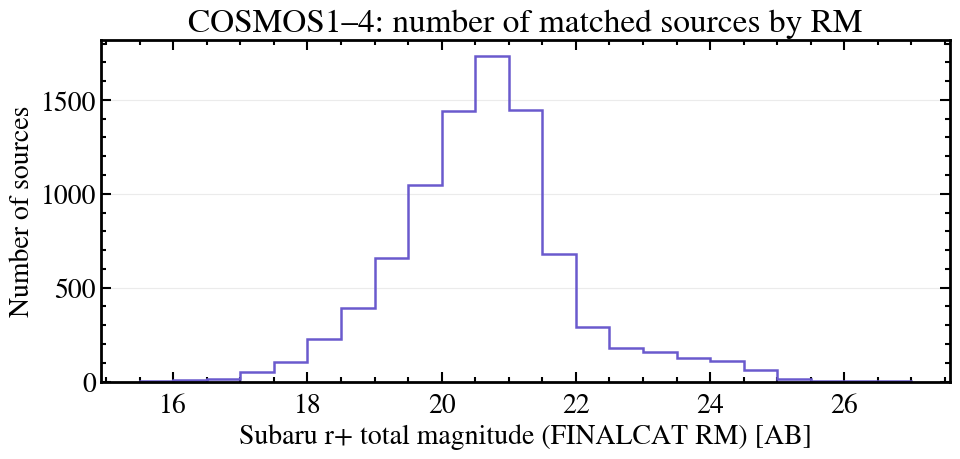

rm_lo,rm_hi,n_sources
float64,float64,int64
15.5,16.0,1
16.0,16.5,6
16.5,17.0,13
17.0,17.5,53
17.5,18.0,104
18.0,18.5,229
18.5,19.0,390
19.0,19.5,656
19.5,20.0,1045


In [11]:
# Use the persisted, cross-field union catalog for all RM statistics.
rm = numeric(combined, 'finalcat_RM')
valid_rm = np.isfinite(rm) & (rm > 0) & (rm < 50)
rm_hist_bin_edges = np.arange(np.floor(rm[valid_rm].min() * 2) / 2,
                              np.ceil(rm[valid_rm].max() * 2) / 2 + 0.5, 0.5)
rm_counts, _ = np.histogram(rm[valid_rm], bins=rm_hist_bin_edges)
rm_source_hist = Table([rm_hist_bin_edges[:-1], rm_hist_bin_edges[1:], rm_counts],
                       names=['rm_lo', 'rm_hi', 'n_sources'])
rm_source_hist.write(ANALYSIS_DIR / 'rm_source_count_histogram.csv', format='ascii.csv', overwrite=True)
print(f'Matched sources without valid RM: {int((~valid_rm).sum()):,} / {len(combined):,}')
fig, ax = plt.subplots(figsize=(10, 5))
ax.hist(rm[valid_rm], bins=rm_hist_bin_edges, histtype='step', color='slateblue', linewidth=1.8)
ax.set(xlabel='Subaru r+ total magnitude (FINALCAT RM) [AB]', ylabel='Number of sources',
       title='COSMOS1–4: number of matched sources by RM')
ax.grid(axis='y', alpha=0.25)
fig.tight_layout()
fig.savefig(ANALYSIS_DIR / 'rm_source_count_histogram.png', dpi=160, bbox_inches='tight')
plt.show()
display(rm_source_hist)

## 2. RM distributions by successfully measured 7DT band

For each band, count a source once when that band has successful photometry in any matched COSMOS field. The full and matched COSMOS FINALCAT RM distributions use shared 0.5-magnitude bins over the full valid magnitude range (0 < RM < 50) and are drawn as lines through bin centers. Only the reference sample N in the legend uses RM <= 21. Both plots use xlim = (16, 21); each y-axis is scaled to the curves visible in that window, including interpolated values at its boundaries, with 8% headroom. Band curves are colored from purple at shorter wavelengths to red at longer wavelengths; a wavelength colorbar replaces a crowded 20-item legend.

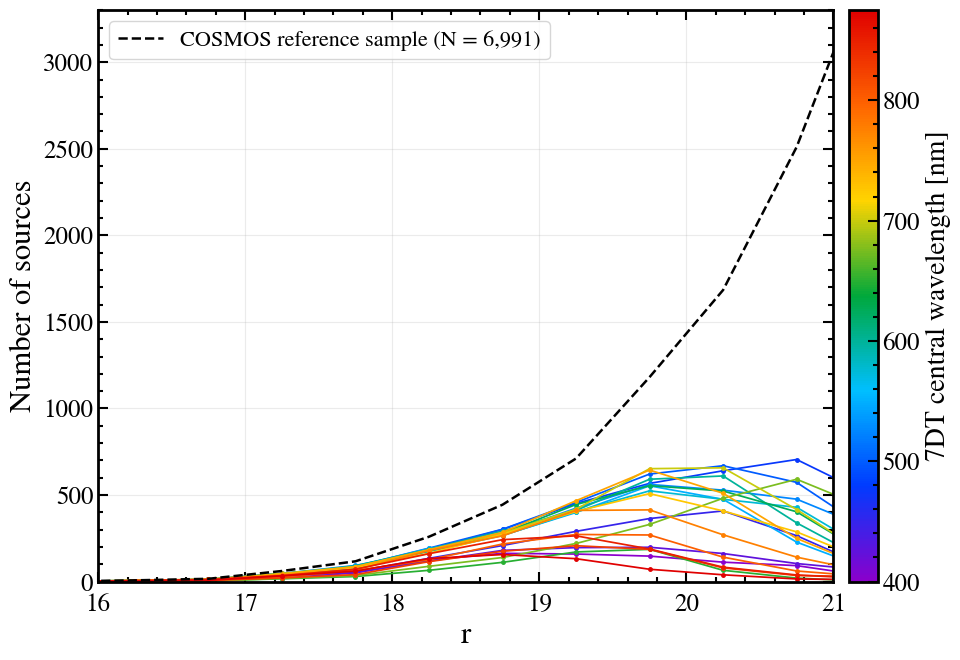

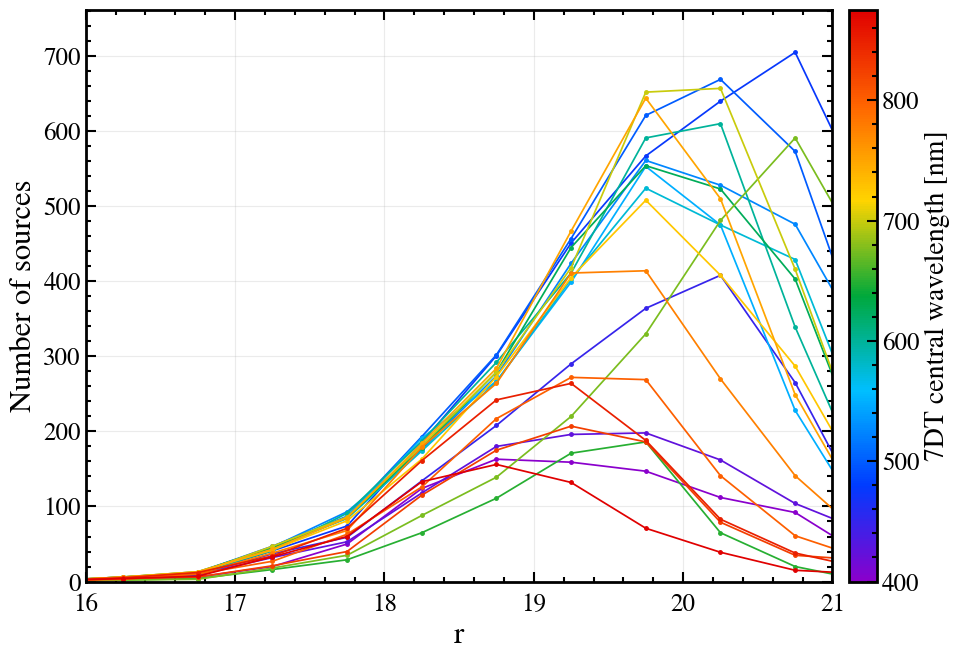

rm_lo,rm_hi,m400_n_sources,m425_n_sources,m450_n_sources,m475_n_sources,m500_n_sources,m525_n_sources,m550_n_sources,m575_n_sources,m600_n_sources,m625_n_sources,m650_n_sources,m675_n_sources,m700_n_sources,m725_n_sources,m750_n_sources,m775_n_sources,m800_n_sources,m825_n_sources,m850_n_sources,m875_n_sources
float64,float64,int64,int64,int64,int64,int64,int64,int64,int64,int64,int64,int64,int64,int64,int64,int64,int64,int64,int64,int64,int64
15.5,16.0,1,1,1,1,1,1,1,1,1,1,0,0,1,1,1,1,1,1,1,1
16.0,16.5,4,4,4,5,4,5,6,5,6,6,2,2,5,6,6,6,3,4,5,4
16.5,17.0,6,9,9,10,12,11,12,12,12,13,4,3,11,13,13,10,10,6,12,7
17.0,17.5,20,32,37,41,47,46,42,45,41,45,16,18,47,42,43,38,27,21,34,33
17.5,18.0,50,53,59,74,87,93,86,84,91,85,29,35,86,81,85,68,63,40,71,60


In [17]:
from matplotlib.colors import LinearSegmentedColormap, Normalize

# Each curve is a per-band union across COSMOS fields, so overlapping fields never double-count a source.
# Load the complete COSMOS FINALCAT so the reference includes sources without a 7DT match.
finalcat_all = Table.read(FINALCAT_PATH)
finalcat_rm = numeric(finalcat_all, 'RM')
# Build histograms over the full valid magnitude range, excluding invalid/sentinel values.
# The r <= 21 cut is used only for the reference sample N in the legend.
rm_limit = 21.0
finalcat_valid_rm = np.isfinite(finalcat_rm) & (finalcat_rm > 0) & (finalcat_rm < 50)
plot_valid_rm = np.isfinite(rm) & (rm > 0) & (rm < 50)
reference_n = int(np.count_nonzero(finalcat_valid_rm & (finalcat_rm <= rm_limit)))
if not finalcat_valid_rm.any():
    raise RuntimeError('No COSMOS FINALCAT sources have valid RM')
# Share 0.5-mag bins across the reference and matched sources over their full valid range.
bin_width = 0.5
all_valid_rm = np.concatenate([finalcat_rm[finalcat_valid_rm], rm[plot_valid_rm]])
rm_bin_min = np.floor(all_valid_rm.min() / bin_width) * bin_width
rm_bin_max = np.ceil(all_valid_rm.max() / bin_width) * bin_width
band_rm_bin_edges = np.arange(rm_bin_min, rm_bin_max + bin_width, bin_width)
rm_bin_centers = (band_rm_bin_edges[:-1] + band_rm_bin_edges[1:]) / 2
band_rm_total_counts, _ = np.histogram(rm[plot_valid_rm], bins=band_rm_bin_edges)
wavelength_nm = np.asarray([int(band[1:]) for band in BANDS_7DT], dtype=float)
purple_to_red = LinearSegmentedColormap.from_list(
    'purple_to_red', ['#8A00CC', '#003BFF', '#00BFFF', '#00A83B', '#FFD400', '#FF6500', '#E00000'])
color_norm = Normalize(vmin=wavelength_nm.min(), vmax=wavelength_nm.max())
finalcat_counts, _ = np.histogram(finalcat_rm[finalcat_valid_rm], bins=band_rm_bin_edges)
per_band_counts = {}
for band, wavelength in zip(BANDS_7DT, wavelength_nm):
    field_success_columns = [np.asarray(combined[f'7dt_cosmos{field}_{band}_success'], dtype=bool)
                             for field in FIELDS]
    measured_anywhere = np.logical_or.reduce(field_success_columns) & plot_valid_rm
    counts, _ = np.histogram(rm[measured_anywhere], bins=band_rm_bin_edges)
    per_band_counts[band] = counts

band_hist_table = Table([band_rm_bin_edges[:-1], band_rm_bin_edges[1:]] +
                        [per_band_counts[band] for band in BANDS_7DT],
                        names=['rm_lo', 'rm_hi'] + [f'{band}_n_sources' for band in BANDS_7DT])
band_hist_table.write(ANALYSIS_DIR / 'rm_source_count_by_band.csv', format='ascii.csv', overwrite=True)
for band, counts in per_band_counts.items():
    assert np.all(counts <= band_rm_total_counts), band
# Keep the visible axis range independent of the histogram bin edges and centers.
plot_xmin, plot_xmax = 16.0, 21.0


def visible_curve_max(counts):
    """Find the largest plotted line value inside xlim, including boundary intersections."""
    # Lines connect bin centers, so interpolate at xlim boundaries rather than using
    # out-of-window bin heights, which can otherwise inflate or clip the visible scale.
    inside = (rm_bin_centers >= plot_xmin) & (rm_bin_centers <= plot_xmax)
    boundary_values = np.interp([plot_xmin, plot_xmax], rm_bin_centers, counts)
    return float(np.max(np.concatenate([counts[inside], boundary_values])))


band_visible_max = max(visible_curve_max(counts) for counts in per_band_counts.values())
plot_ymax = max(1.0, visible_curve_max(finalcat_counts), band_visible_max) * 1.08
scalar_map = plt.cm.ScalarMappable(norm=color_norm, cmap=purple_to_red)
scalar_map.set_array([])

# Render the RM distribution with a linear y axis.
fig, ax = plt.subplots(figsize=(10, 7))
ax.plot(rm_bin_centers, finalcat_counts, color='black', linestyle='--', linewidth=1.8,
        label=f'COSMOS reference sample (N = {reference_n:,})', zorder=4)
for band, wavelength in zip(BANDS_7DT, wavelength_nm):
    ax.plot(rm_bin_centers, per_band_counts[band], marker='o', markersize=2.5,
            linewidth=1.25, color=purple_to_red(color_norm(wavelength)))
ax.set_xlabel('r', fontsize=22)
ax.set_ylabel('Number of sources', fontsize=22)
ax.tick_params(axis='both', labelsize=18)
ax.set_xlim(plot_xmin, plot_xmax)
ax.set_ylim(0, plot_ymax)
ax.grid(alpha=0.25)
ax.legend(loc='upper left', fontsize=16)
colorbar = fig.colorbar(scalar_map, ax=ax, orientation='vertical', pad=0.02, fraction=0.05)
colorbar.set_label('7DT central wavelength [nm]', fontsize=20)
colorbar.ax.tick_params(labelsize=18)
fig.tight_layout()
fig.savefig(ANALYSIS_DIR / 'rm_source_count_by_band.png', dpi=160, bbox_inches='tight')
plt.show()
plt.close(fig)

# Show the per-band distributions alone, without the all-COSMOS FINALCAT reference.
fig, ax = plt.subplots(figsize=(10, 7))
for band, wavelength in zip(BANDS_7DT, wavelength_nm):
    ax.plot(rm_bin_centers, per_band_counts[band], marker='o', markersize=2.5,
            linewidth=1.25, color=purple_to_red(color_norm(wavelength)))
ax.set_xlabel('r', fontsize=22)
ax.set_ylabel('Number of sources', fontsize=22)
ax.tick_params(axis='both', labelsize=18)
ax.set_xlim(plot_xmin, plot_xmax)
ax.set_ylim(0, max(1.0, band_visible_max) * 1.08)
ax.grid(alpha=0.25)
colorbar = fig.colorbar(scalar_map, ax=ax, orientation='vertical', pad=0.02, fraction=0.05)
colorbar.set_label('7DT central wavelength [nm]', fontsize=20)
colorbar.ax.tick_params(labelsize=18)
fig.tight_layout()
fig.savefig(ANALYSIS_DIR / 'rm_source_count_by_band_only.png', dpi=160, bbox_inches='tight')
plt.show()
plt.close(fig)
display(band_hist_table[:5])


## 3. Histogram of successfully measured bands

Each source's count is the number of distinct 7DT bands successfully measured in at least one matched COSMOS field. A source is counted once per band even when overlapping fields both measured it.

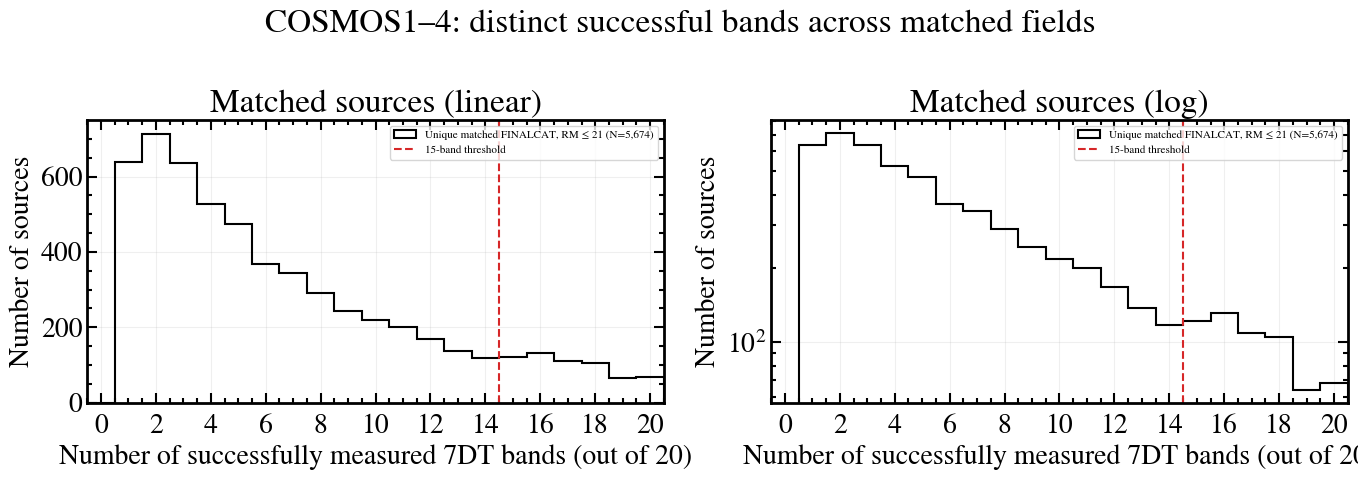

n_success_bands,n_matched_finalcat
int64,int64
0,0
1,638
2,714
3,637
4,526
5,473
6,367
7,343
8,290


In [39]:
# Make a temporary RM-limited catalog for this histogram only.
rm_column = combined['finalcat_RM']
rm_values = np.asarray(np.ma.filled(rm_column, np.nan), dtype=float)
valid_rm = (~np.ma.getmaskarray(rm_column) & np.isfinite(rm_values) &
            (rm_values > 0) & (rm_values <= 21))
combined_tmp = combined[valid_rm]
band_bins = np.arange(-0.5, N_TOTAL_BANDS + 1.5, 1)

n_success = np.asarray(combined_tmp['n_success_bands'])
counts_matched, _ = np.histogram(n_success, bins=band_bins)
hist_table = Table([np.arange(N_TOTAL_BANDS + 1), counts_matched], names=['n_success_bands', 'n_matched_finalcat'])
hist_table.write(ANALYSIS_DIR / 'band_count_histogram.csv', format='ascii.csv', overwrite=True)
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
for ax, log in zip(axes, (False, True)):
    ax.hist(n_success, bins=band_bins, histtype='step', color='black', linewidth=1.5,
            label=f'Unique matched FINALCAT, RM ≤ 21 (N={len(combined_tmp):,})')
    ax.axvline(MIN_SUCCESS_BANDS - 0.5, color='tab:red', linestyle='--', label='15-band threshold')
    ax.set(xlabel='Number of successfully measured 7DT bands (out of 20)', ylabel='Number of sources',
           xticks=np.arange(0, 21, 2), xlim=(-0.5, 20.5), title='Matched sources (log)' if log else 'Matched sources (linear)')
    if log: ax.set_yscale('log')
    ax.grid(alpha=0.2)
    ax.legend(fontsize=8)
fig.suptitle('COSMOS1–4: distinct successful bands across matched fields')
fig.tight_layout()
fig.savefig(ANALYSIS_DIR / 'successful_band_count_histogram.png', dpi=160, bbox_inches='tight')
plt.show()
display(hist_table)

## 4. r magnitude: ≥15 successful bands versus all matched sources

Both populations use `finalcat_RM` from the saved catalog, with finite `0 < RM < 50`. Missing RM values are reported and excluded from both magnitude histograms.

Matched sources without valid RM: 583
>=15-band sources without valid RM: 413


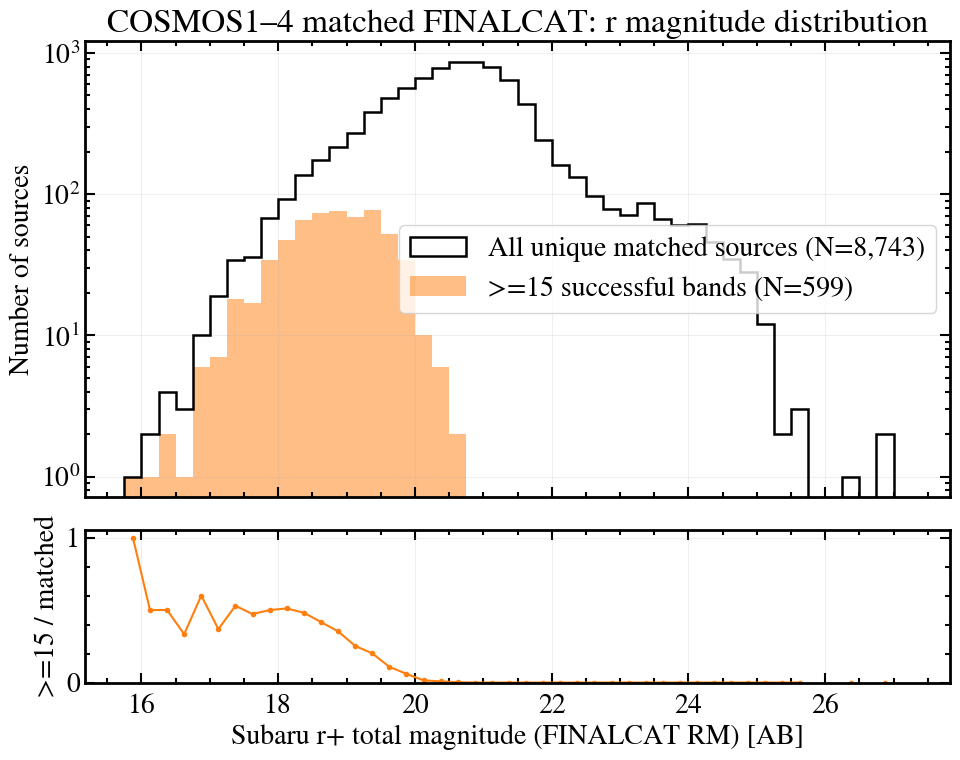

In [40]:
rm = numeric(combined, 'finalcat_RM')
valid_rm = np.isfinite(rm) & (rm > 0) & (rm < 50)
all_rm_mask = matched_mask & valid_rm
subset_rm_mask = ge15_mask & valid_rm
print(f'Matched sources without valid RM: {int((matched_mask & ~valid_rm).sum())}')
print(f'>=15-band sources without valid RM: {int((ge15_mask & ~valid_rm).sum())}')
if not all_rm_mask.any():
    raise RuntimeError('No valid FINALCAT RM values in matched catalog')
mag_bins = np.arange(np.floor(rm[all_rm_mask].min() * 4) / 4,
                     np.ceil(rm[all_rm_mask].max() * 4) / 4 + 0.5, 0.25)
all_counts, _ = np.histogram(rm[all_rm_mask], bins=mag_bins)
subset_counts, _ = np.histogram(rm[subset_rm_mask], bins=mag_bins)
assert all_counts.sum() == int(all_rm_mask.sum())
assert subset_counts.sum() == int(subset_rm_mask.sum())
assert (subset_counts <= all_counts).all()
fraction = np.divide(subset_counts, all_counts, out=np.full(len(all_counts), np.nan), where=all_counts > 0)
mag_hist = Table([mag_bins[:-1], mag_bins[1:], all_counts, subset_counts, fraction],
                 names=['rm_lo', 'rm_hi', 'n_all_matched', 'n_ge15_bands', 'fraction_ge15'])
mag_hist.write(ANALYSIS_DIR / 'rm_histogram_ge15_vs_all_matched.csv', format='ascii.csv', overwrite=True)
fig, axes = plt.subplots(2, 1, figsize=(10, 8), sharex=True, gridspec_kw={'height_ratios': [3, 1]})
axes[0].hist(rm[all_rm_mask], bins=mag_bins, histtype='step', color='black', linewidth=1.8,
             label=f'All unique matched sources (N={int(all_rm_mask.sum()):,})')
axes[0].hist(rm[subset_rm_mask], bins=mag_bins, color='tab:orange', alpha=0.5,
             label=f'>=15 successful bands (N={int(subset_rm_mask.sum()):,})')
axes[0].set(yscale='log', ylabel='Number of sources', title='COSMOS1–4 matched FINALCAT: r magnitude distribution')
axes[0].legend()
axes[1].plot((mag_bins[:-1] + mag_bins[1:]) / 2, fraction, 'o-', color='tab:orange', markersize=3)
axes[1].set(xlabel='Subaru r+ total magnitude (FINALCAT RM) [AB]', ylabel='>=15 / matched', ylim=(0, 1.05))
for ax in axes: ax.grid(alpha=0.2)
fig.tight_layout()
fig.savefig(ANALYSIS_DIR / 'rm_histogram_ge15_vs_all_matched.png', dpi=160, bbox_inches='tight')
plt.show()

## 5. Select a catalog, then inspect its sources

Edit the selection condition below, then call `plot_SourceInfoFromCatalog` once
per source. `master` is the catalog already reloaded from the saved unified FITS.
The method selects the representative COSMOS image internally; all metadata and
comparison populations come from the supplied catalog, including reconciled SDSS.

Each call displays two portrait A4 pages. `save_pdf=True` also saves the same two
pages as one source PDF; `show=False` saves without notebook display. Global IDs
are preserved. Across-field band counts are labelled separately from the
representative field's photometry. The shared implementation is in
`sourceinfo_report.py` next to this notebook.


In [41]:
# Shared report layout keeps notebooks 2.2 and 2.3 consistent.
import sys
if str(PROJECT_ROOT / 'Notebooks') not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT / 'Notebooks'))
from sourceinfo_report import SourceInfoResult, plot_source_info as _plot_source_info

def plot_SourceInfoFromCatalog(
    cat, image=None, pixel_range=40, source_id=None, *,
    info_catalog=None, population_catalog=None, diagnostic_band='m600', show=True,
    save_pdf=False, output_dir=None,
):
    """Show all source information as two portrait A4 report pages.

    Set save_pdf=True for one automatically named PDF per source, or pass a PDF
    path. output_dir changes the automatic destination. With show=False only
    saving/returning is performed. Without source_id a random source is selected.
    """
    return _plot_source_info(
        cat, image=image, pixel_range=pixel_range, source_id=source_id,
        info_catalog=info_catalog, population_catalog=population_catalog,
        diagnostic_band=diagnostic_band, show=show, save_pdf=save_pdf,
        output_dir=output_dir, project_root=PROJECT_ROOT,
    )


def plot_SourceImgFromCatalog(cat, image=None, pixel_range=None, source_id=None, show=True):
    '''Plot a detection-image cutout centered on a selected catalog source.'''
    if image is None:
        image = detection_image
    if len(cat) == 0:
        raise ValueError('The input catalog is empty.')
    required = {'master_id', 'master_x', 'master_y'}
    missing = required.difference(cat.colnames)
    if missing:
        raise KeyError(f'Catalog is missing required columns: {sorted(missing)}')
    if pixel_range is not None and (not np.isfinite(pixel_range) or pixel_range <= 0):
        raise ValueError('pixel_range must be None or a positive number.')
    master_ids = np.asarray(cat['master_id'], dtype=np.int64)
    if source_id is None:
        selected_index = int(np.random.default_rng().integers(len(cat)))
    else:
        matches = np.flatnonzero(master_ids == int(source_id))
        if len(matches) == 0:
            raise KeyError(f'master_id={source_id} is not present in the catalog.')
        selected_index = int(matches[0])
    x_all = np.ma.filled(cat['master_x'], np.nan).astype(float)
    y_all = np.ma.filled(cat['master_y'], np.nan).astype(float)
    selected_x, selected_y = float(x_all[selected_index]), float(y_all[selected_index])
    if not np.isfinite(selected_x) or not np.isfinite(selected_y):
        raise ValueError('The selected source has a non-finite pixel position.')
    if pixel_range is None:
        xmin, xmax, ymin, ymax = 0, image.shape[1], 0, image.shape[0]
    else:
        center_x, center_y = int(round(selected_x - 1)), int(round(selected_y - 1))
        half = int(round(pixel_range))
        xmin, xmax = max(0, center_x - half), min(image.shape[1], center_x + half + 1)
        ymin, ymax = max(0, center_y - half), min(image.shape[0], center_y + half + 1)
    finite = np.isfinite(x_all) & np.isfinite(y_all)
    in_view = finite & (x_all - 1 >= xmin) & (x_all - 1 < xmax) & (y_all - 1 >= ymin) & (y_all - 1 < ymax)
    crop = image[ymin:ymax, xmin:xmax]
    fig, ax = plt.subplots(figsize=(6, 6))
    ax.imshow(crop, origin='lower', cmap='gray', norm=ImageNormalize(image, interval=ZScaleInterval()), extent=[xmin + 0.5, xmax + 0.5, ymin + 0.5, ymax + 0.5])
    class_colors = {'matched': 'purple', '7dt_only': 'tab:red', 'finalcat_only': 'tab:blue'}
    classes = np.asarray(cat['master_class']).astype(str) if 'master_class' in cat.colnames else np.full(len(cat), 'source')
    for source_class in np.unique(classes[in_view]):
        selected = in_view & (classes == source_class)
        ax.scatter(x_all[selected], y_all[selected], s=24, facecolors='none', edgecolors=class_colors.get(source_class, 'tab:red'), linewidths=0.8, label=f'{source_class} ({int(selected.sum())})')
    ax.scatter(selected_x, selected_y, marker='+', s=180, color='cyan', linewidths=1.5, label=f'master_id={master_ids[selected_index]}')
    ax.set(xlabel='X pixel', ylabel='Y pixel')
    title_class = classes[selected_index]
    view_label = 'whole image' if pixel_range is None else f'pixel_range={pixel_range}'
    ax.set_title(f'{title_class}: master_id={master_ids[selected_index]} ({view_label})')
    ax.legend(loc='upper right')
    fig.tight_layout()
    if show:
        plt.show()
    return fig, ax, int(master_ids[selected_index])

def _sn5_limit(centers, medians, level=5.0):
    # Median S/N falls with magnitude; linearly interpolate the bright-to-faint
    # crossing of the S/N = level line. Returns nan when there is no crossing.
    c = np.asarray(centers, dtype=float)
    m = np.asarray(medians, dtype=float)
    ok = np.isfinite(c) & np.isfinite(m)
    c, m = c[ok], m[ok]
    if c.size < 2:
        return np.nan
    order = np.argsort(c)
    c, m = c[order], m[order]
    below = np.where(m < level)[0]
    if below.size == 0 or np.all(m < level):
        return np.nan
    i = int(below[0])
    if i == 0 or not (m[i - 1] >= level > m[i]):
        return np.nan
    c0, m0, c1, m1 = c[i - 1], m[i - 1], c[i], m[i]
    return float(c0 + (level - m0) * (c1 - c0) / (m1 - m0))


In [42]:
# 1. Edit the catalog selection here. This does not modify the saved master.
master = combined
selected = master[~np.asarray(master['all_20_success'], dtype=bool)]

# Pick reproducible examples from the selected population (at most N_EXAMPLES).
rng = np.random.default_rng(RANDOM_SEED)
examples = selected[rng.choice(len(selected), size=min(N_EXAMPLES, len(selected)), replace=False)]
display(examples[['master_id', 'finalcat_ID', 'finalcat_RM', 'selected_COSMOS', 'n_success_bands']])


master_id,finalcat_ID,finalcat_RM,selected_COSMOS,n_success_bands
int64,bytes20,float32,int16,int16
5341,149.504558+02.125052,17.98286,1,7
6126,150.421975+02.071574,20.526274,1,5
2551,149.843875+01.777351,17.768358,1,18
7256,150.370028+01.983678,19.819874,1,3
3625,149.782626+02.749855,21.148605,2,2


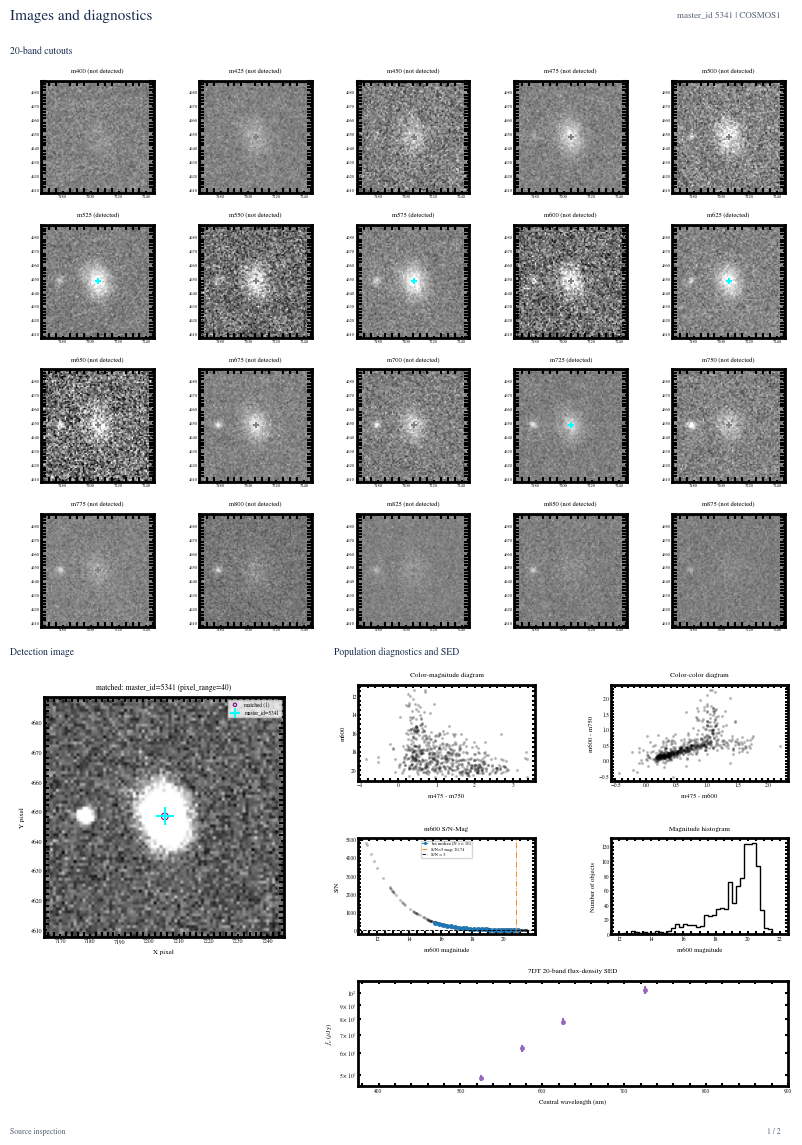

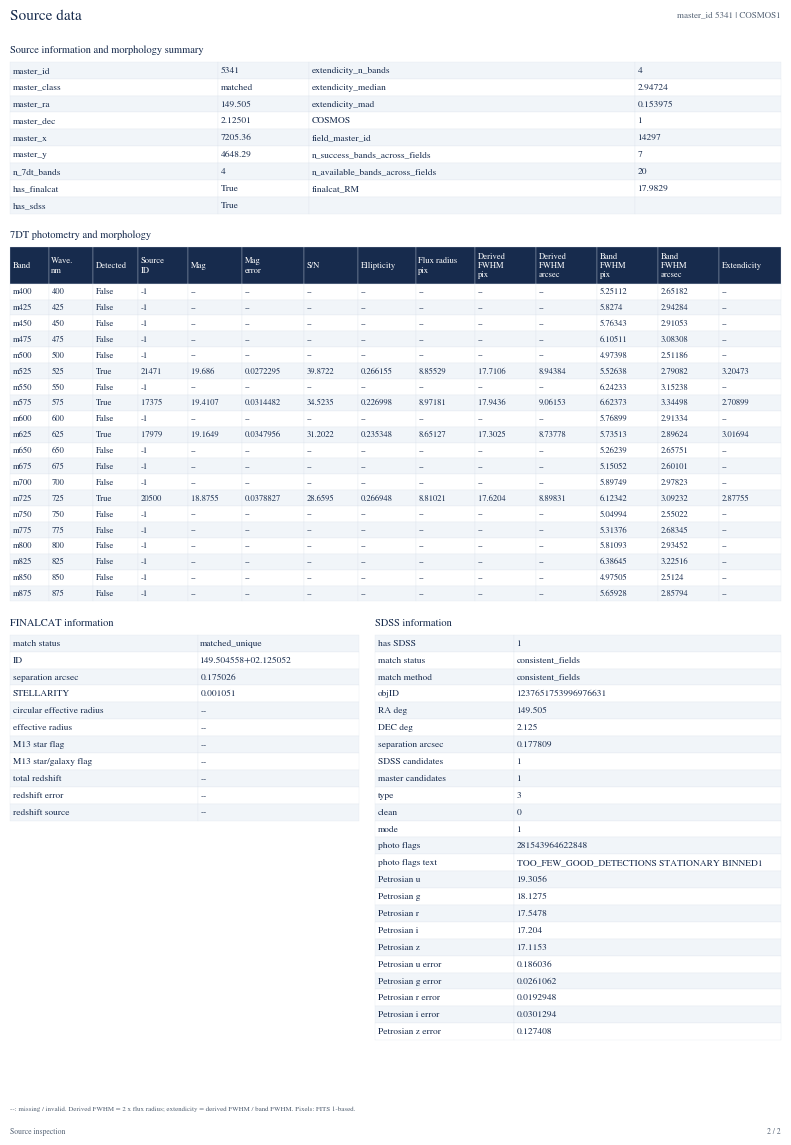

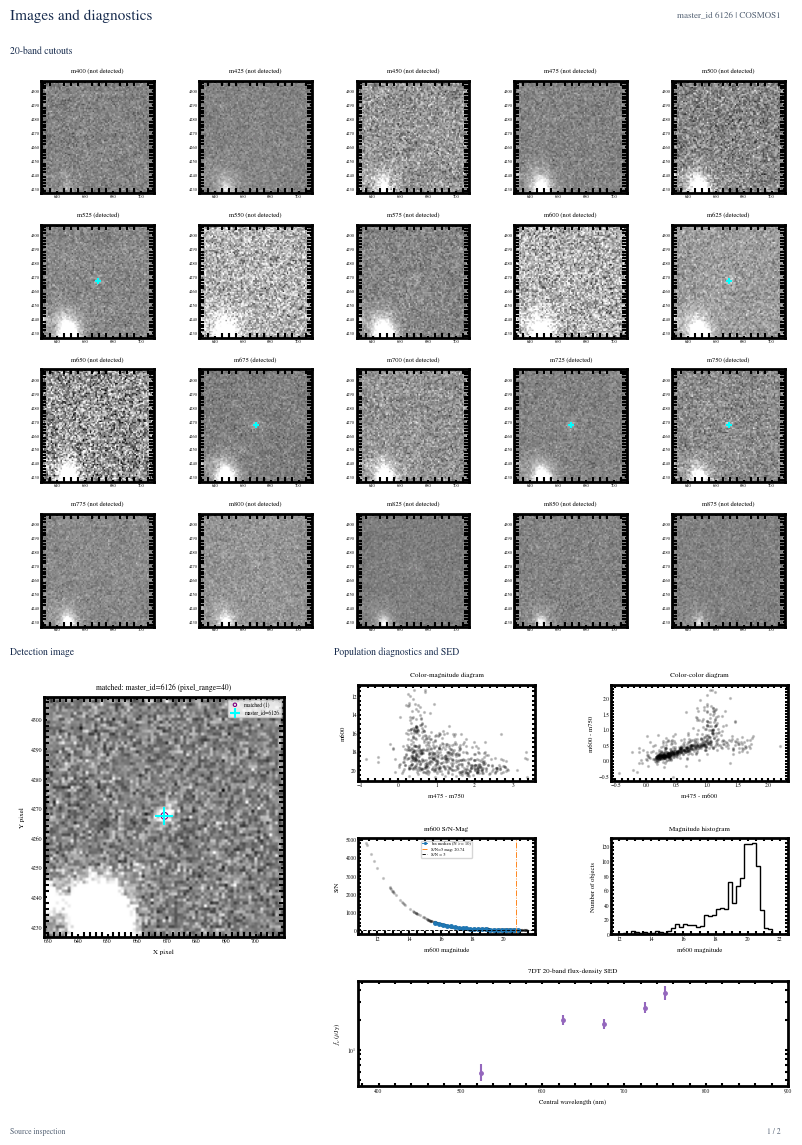

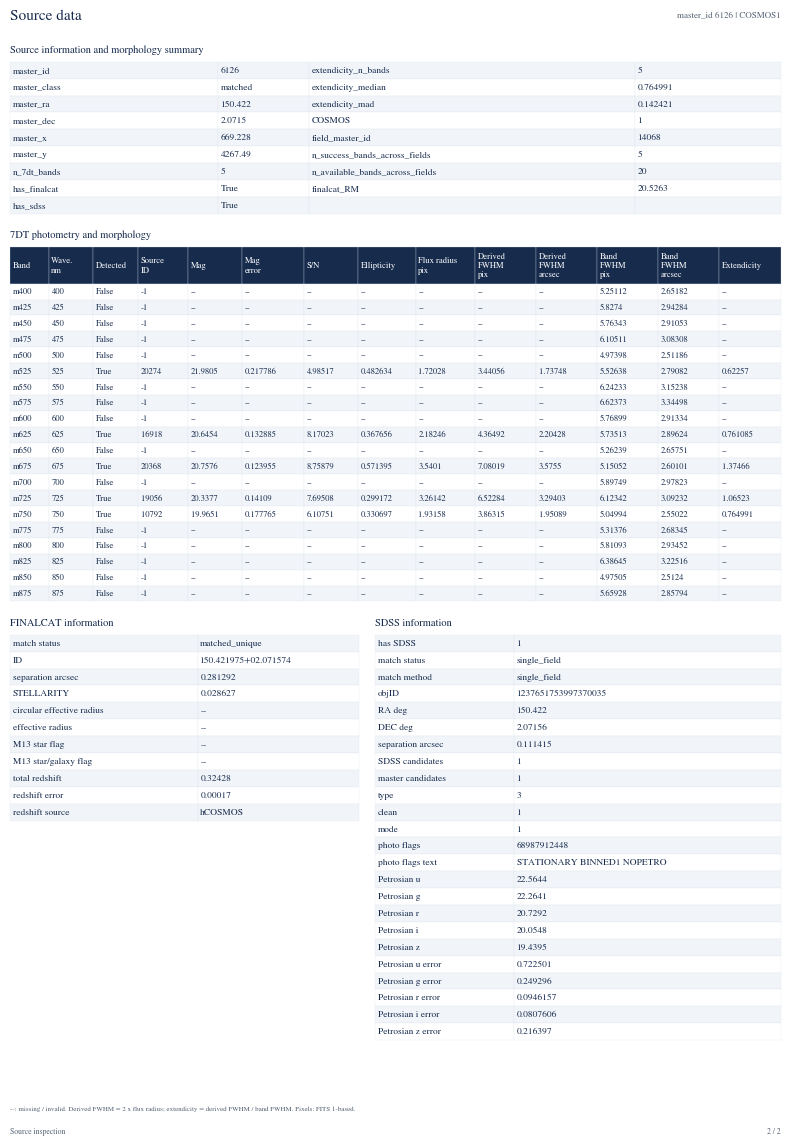

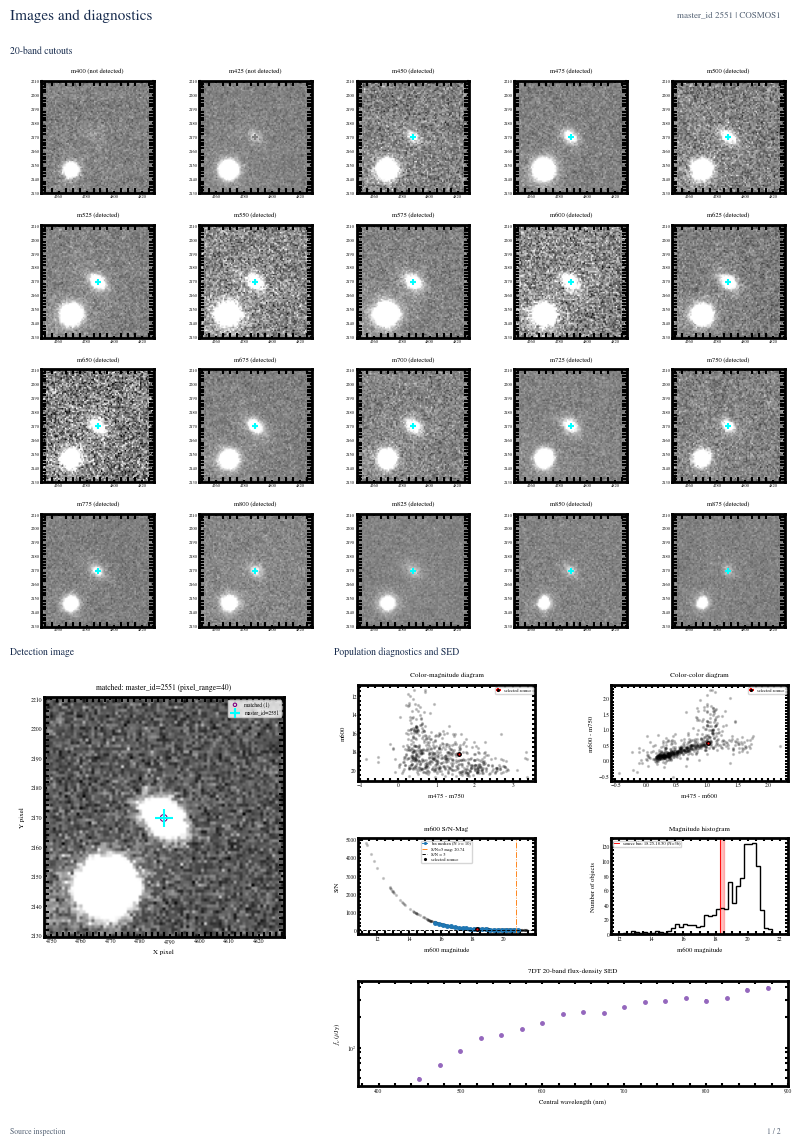

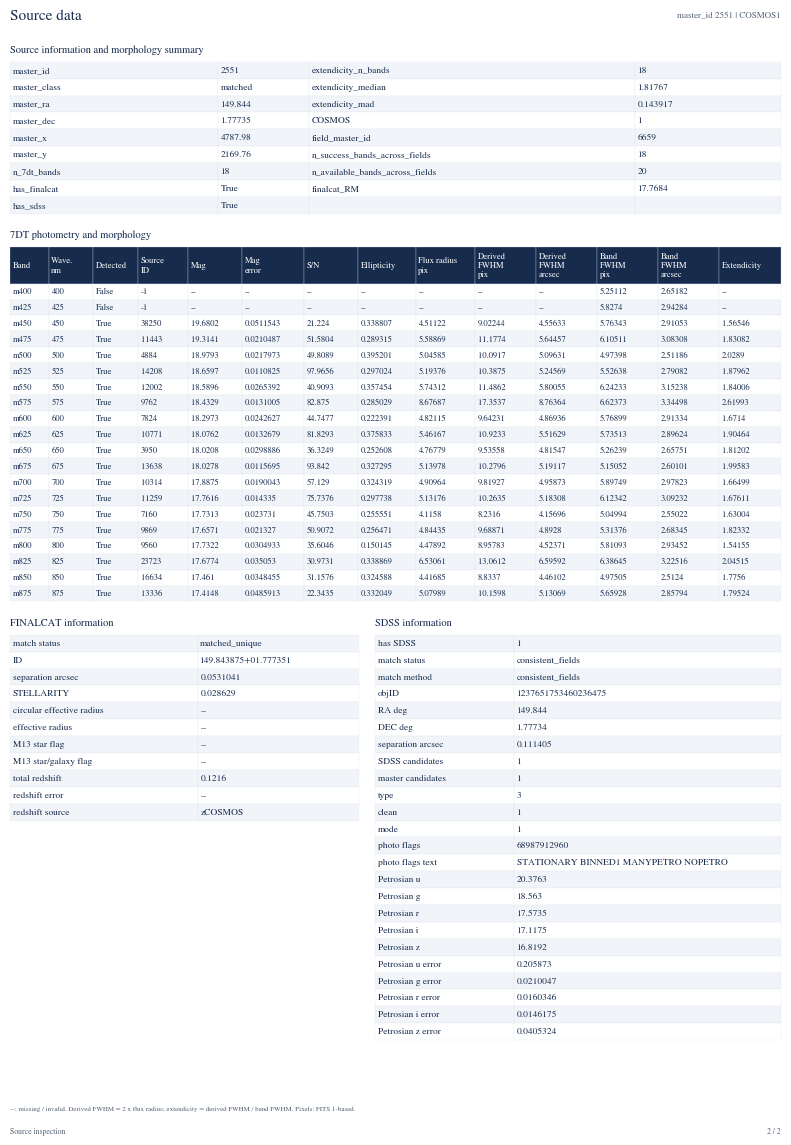

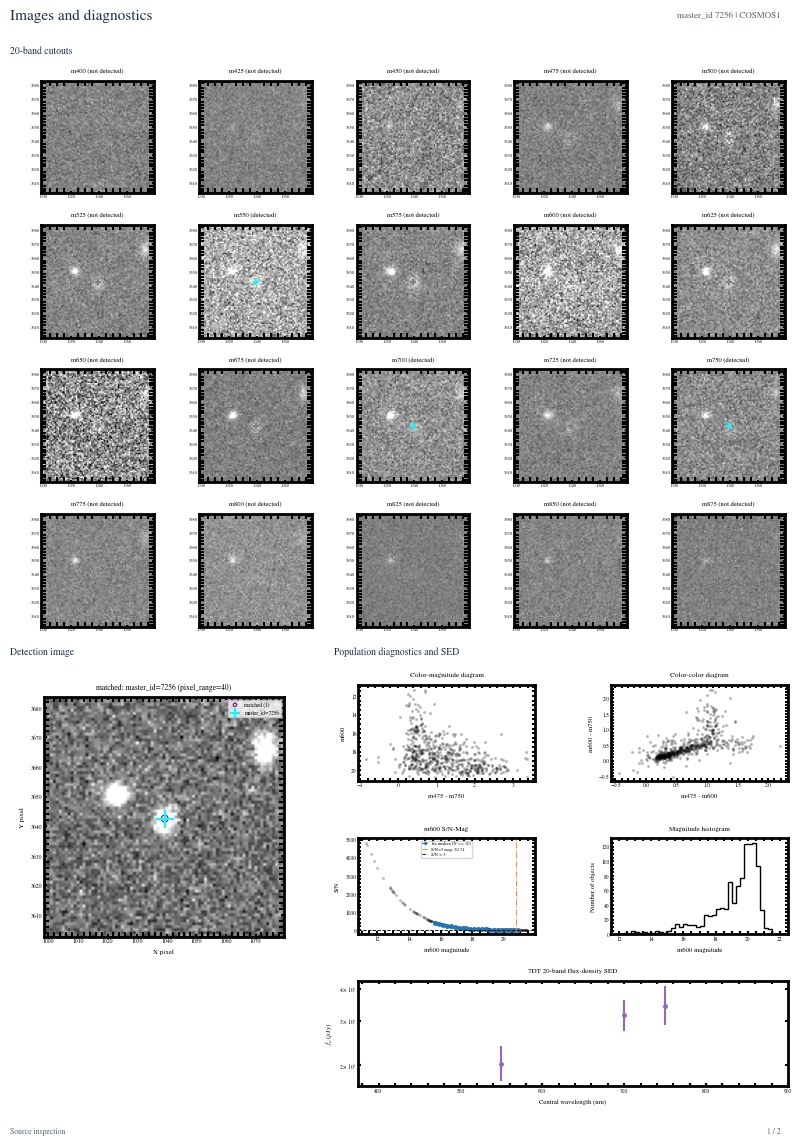

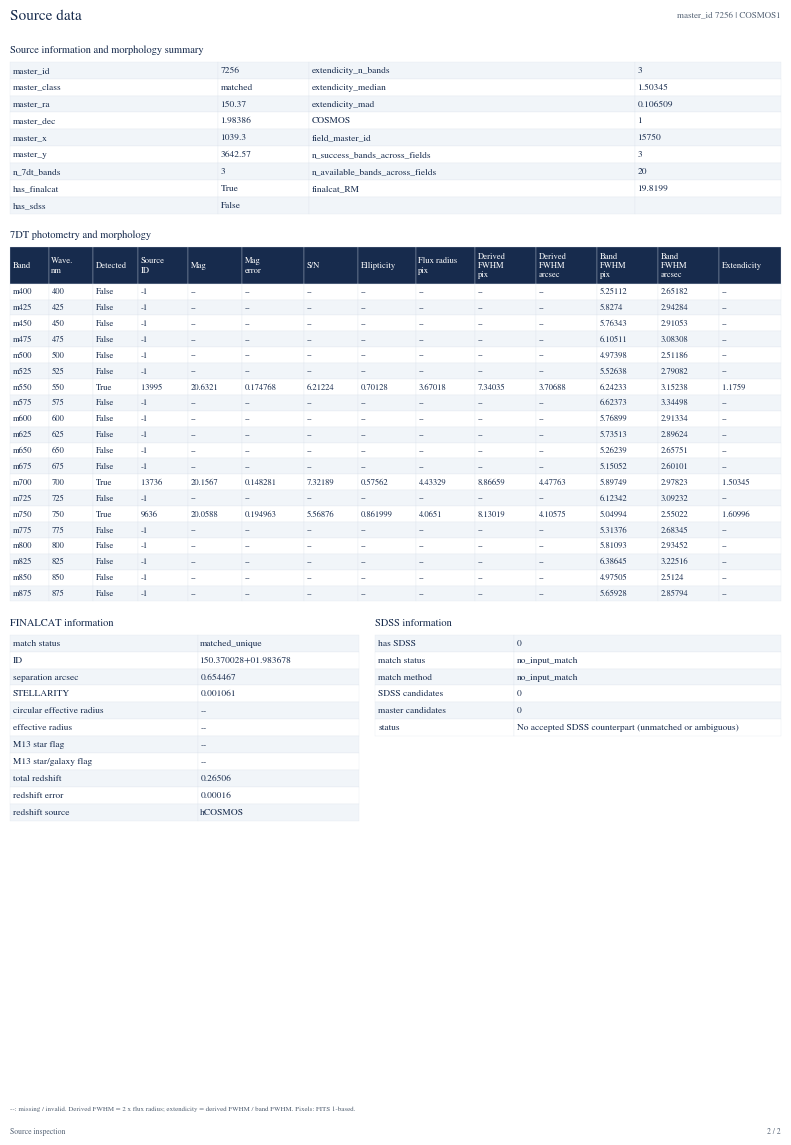

KeyboardInterrupt: 

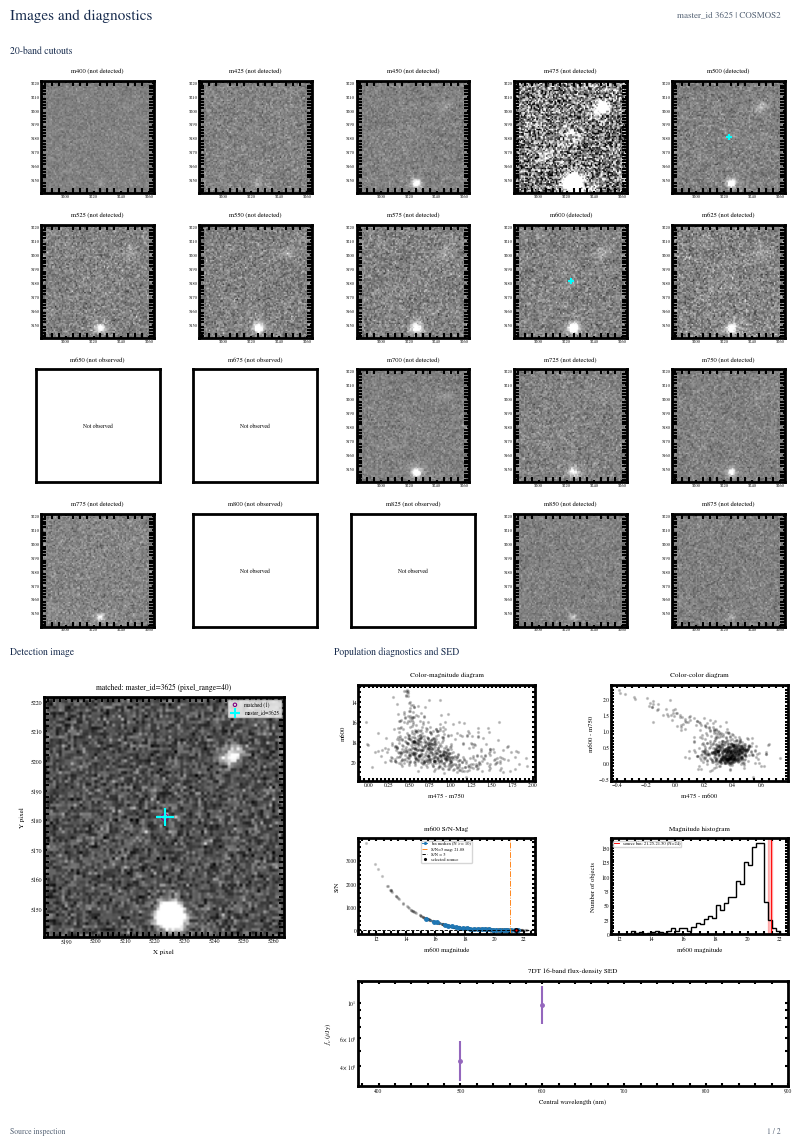

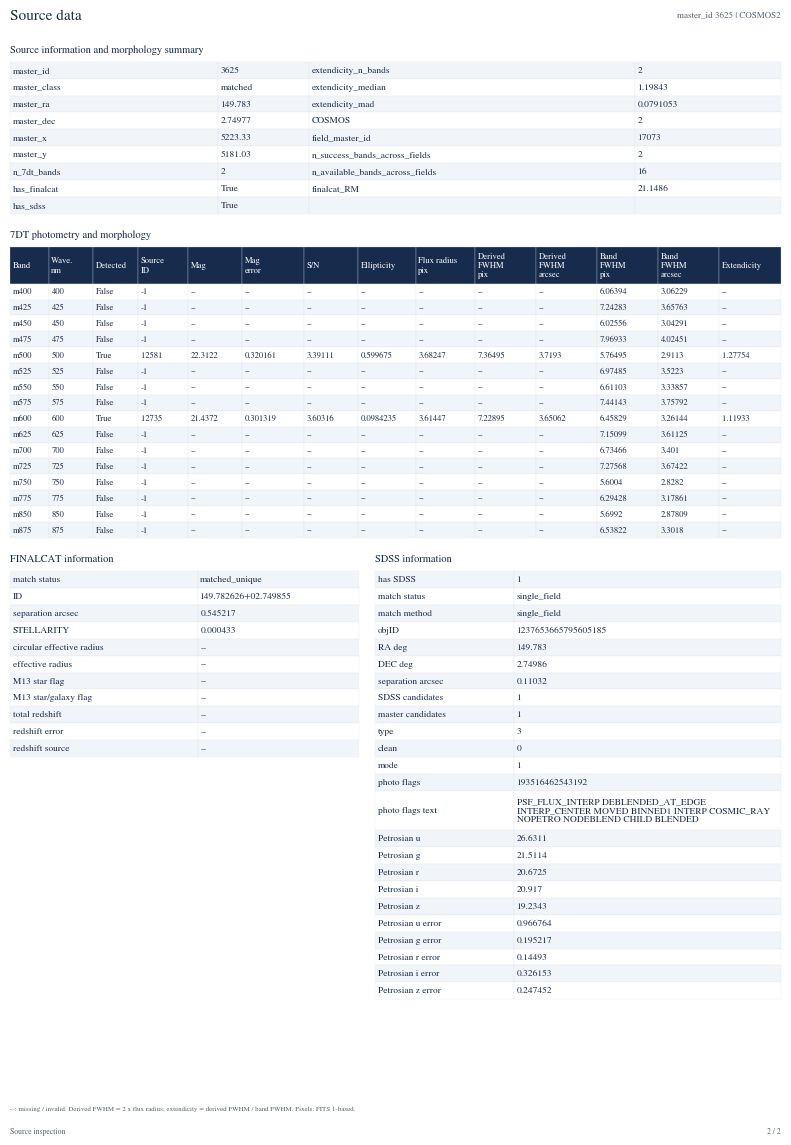

In [43]:
# 2. One call displays every table and plot, and saves one PDF for this source.
for source_id in examples['master_id']:
    source_info = plot_SourceInfoFromCatalog(
        examples,
        source_id=int(source_id),
        pixel_range=PIXEL_RANGE,
        population_catalog=master,
        save_pdf=True,
        output_dir=EXAMPLE_DIR,
    )
